# 6 · Validazione su scansioni di test e limite del setup

Finora i numeri sui dati reali venivano da due scansioni (Corpo 5 e Corpo 6), le stesse su cui ho scelto e regolato gli algoritmi: sono errori di **sviluppo**, ottimistici. Le 33 scansioni contengono però tutti e sei i solidi di cui ho i disegni. `data/scans.csv` elenca le 14 che corrispondono a un solido noto; le due di sviluppo sono marcate `dev`, le altre 12 `test` e non hanno guidato nessuna scelta.

> [!NOTE]
> I solidi nelle scansioni sono stati riconosciuti automaticamente: per ogni scansione si è scelto il profilo nominale con la distanza minima, tenendo quelle con errore mediano sotto 1.6 mm e almeno 150 punti sul solido. Il riconoscimento ha un pregiudizio verso errori bassi, e le altre 19 scansioni non corrispondono a nessuno dei sei profili (probabilmente il Corpo 7, con il foro, o pose fuori dal piano di misura) e non sono usate. I solidi sono inoltre stampati in FDM, con una tolleranza propria dell'ordine di 0.2-0.3 mm.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "docs" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.calibration import distort_points, project
from lightsheet3d.dataset import Dataset
from lightsheet3d.evaluate import evaluate, summarize
from lightsheet3d.laser import laser_centroids
from lightsheet3d.scanner import Calibration, Scanner
from lightsheet3d.solids import SOLIDS, nominal_curve

dataset = Dataset.load(ROOT / "data" / "dataset.toml")
calibration = Calibration.fit(dataset)
results = evaluate(calibration, dataset)
for by in ("role", "solid"):
    print(f"per {by}:")
    for key, s in summarize(results, by).items():
        print(f"  {key:7s} {s['scans']:2d} scansioni  distanza mediana (media) {s['median']:.2f} mm, al peggio {s['worst']:.2f} mm  |  altezze dei picchi: errore medio {s['height_mean']:+.2f} mm, rms {s['height_rms']:.2f} mm")

per role:
  dev      2 scansioni  distanza mediana (media) 0.58 mm, al peggio 0.62 mm  |  altezze dei picchi: errore medio -0.33 mm, rms 0.58 mm
  test    12 scansioni  distanza mediana (media) 0.91 mm, al peggio 1.54 mm  |  altezze dei picchi: errore medio -0.15 mm, rms 0.75 mm
per solid:
  corpo1   2 scansioni  distanza mediana (media) 1.34 mm, al peggio 1.54 mm  |  altezze dei picchi: errore medio +nan mm, rms nan mm
  corpo2   2 scansioni  distanza mediana (media) 0.67 mm, al peggio 0.91 mm  |  altezze dei picchi: errore medio -0.35 mm, rms 0.35 mm
  corpo3   4 scansioni  distanza mediana (media) 0.66 mm, al peggio 0.79 mm  |  altezze dei picchi: errore medio -0.31 mm, rms 0.87 mm
  corpo4   2 scansioni  distanza mediana (media) 1.01 mm, al peggio 1.33 mm  |  altezze dei picchi: errore medio +0.07 mm, rms 0.68 mm
  corpo5   2 scansioni  distanza mediana (media) 0.90 mm, al peggio 1.17 mm  |  altezze dei picchi: errore medio +0.03 mm, rms 0.33 mm
  corpo6   2 scansioni  distanza med

## Errore per scansione, con e senza allungamento obliquo

Con `oblique=True` il profilo nominale può allungarsi lungo Y: serve quando il solido è posato di traverso rispetto alla lama, perché il taglio è obliquo e il profilo misurato risulta allungato di 1/cos(angolo). La scala trovata è un parametro di posizionamento e si riporta sempre: per le scansioni ben allineate deve venire 1.00, ed è un controllo indipendente della scala di Y della calibrazione.

scansione  solido  ruolo  mediana  obliquo allungamento inclinazione
30o3       corpo5  dev       0.62     0.62         1.03         14°
30o34      corpo6  dev       0.55     0.68         1.00          0°
30o5       corpo5  test      1.17     1.31         1.15         30°
30o37      corpo6  test      1.07     0.91         1.09         23°
30o30      corpo3  test      0.79     0.81         1.00          0°
30o31      corpo3  test      0.48     0.56         1.00          0°
30o32      corpo3  test      0.74     0.43         1.07         21°
30o33      corpo3  test      0.63     0.63         1.00          0°
30o7       corpo2  test      0.44     0.44         1.00          0°
30o8       corpo2  test      0.91     0.75         1.17         31°
30o11      corpo4  test      1.33     0.89         1.33         41°
30o12      corpo4  test      0.70     0.70         1.00          0°
30o14      corpo1  test      1.14     1.16         1.00          0°
30o15      corpo1  test      1.54     1.01     

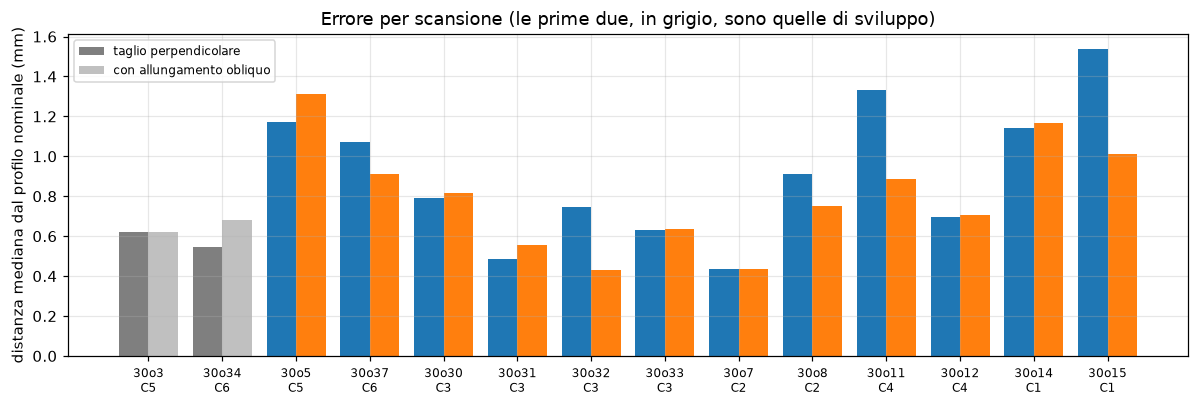

In [2]:
oblique = evaluate(calibration, dataset, oblique=True)
print(f"{'scansione':10s} {'solido':7s} {'ruolo':5s} {'mediana':>8s} {'obliquo':>8s} {'allungamento':>12s} {'inclinazione':>12s}")
for a, b in zip(results, oblique):
    tilt = np.degrees(np.arccos(min(1, 1 / b.scale)))
    print(f"{a.file[:-4]:10s} {a.solid:7s} {a.role:5s} {a.median:8.2f} {b.median:8.2f} {b.scale:12.2f} {tilt:10.0f}°")
test = [(a.median, b.median, b.scale) for a, b in zip(results, oblique) if a.role == "test"]
print(f"test: mediana media {np.mean([t[0] for t in test]):.2f} mm -> {np.mean([t[1] for t in test]):.2f} mm con l'allungamento")

fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(results))
ax.bar(x - 0.2, [r.median for r in results], 0.4, color=["tab:gray" if r.role == "dev" else "tab:blue" for r in results], label="taglio perpendicolare")
ax.bar(x + 0.2, [r.median for r in oblique], 0.4, color=["silver" if r.role == "dev" else "tab:orange" for r in results], label="con allungamento obliquo")
ax.set_xticks(x, [f"{r.file[:-4]}\n{r.solid.replace('corpo', 'C')}" for r in results], fontsize=8)
ax.set(ylabel="distanza mediana dal profilo nominale (mm)", title="Errore per scansione (le prime due, in grigio, sono quelle di sviluppo)")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "heldout_scans.png", bbox_inches="tight")

## Un profilo per solido

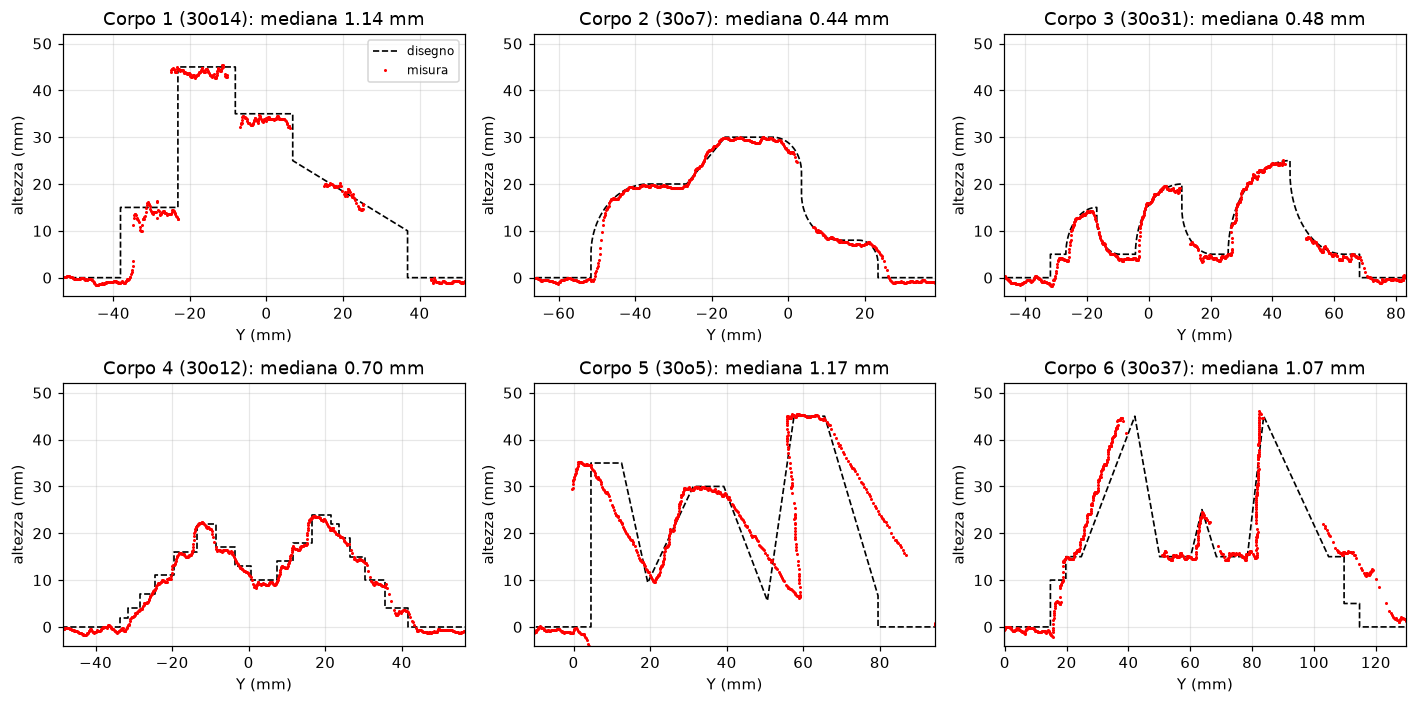

In [3]:
PICK = {"corpo1": "30o14.jpg", "corpo2": "30o7.jpg", "corpo3": "30o31.jpg", "corpo4": "30o12.jpg", "corpo5": "30o5.jpg", "corpo6": "30o37.jpg"}
scanner = Scanner(calibration)
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (key, name) in zip(axs.ravel(), PICK.items()):
    profile, solid = scanner.scan(dataset.scans_path / name), SOLIDS[key]
    comparison = profile.compare(solid)
    yn, hn = nominal_curve(solid, comparison.sign, comparison.shift, pad=40)
    ax.plot(yn, hn, "k--", lw=1.1, label="disegno")
    ax.plot(profile.y, profile.height, "r.", ms=2, label="misura")
    span = (comparison.sign * solid.outline[:, 0] + comparison.shift)
    ax.set(xlim=(span.min() - 15, span.max() + 15), ylim=(-4, 52), title=f"{solid.name} ({name[:-4]}): mediana {comparison.median:.2f} mm")
    ax.set_xlabel("Y (mm)"); ax.set_ylabel("altezza (mm)")
axs[0, 0].legend(loc="upper right", fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "heldout_profiles.png", bbox_inches="tight")

## Il limite del setup

Tre misure, tutte sui dati reali, spiegano perché l'errore non scende sotto circa 0.5-1 mm.

1. Sensibilità: la lama si sposta di 0.79 px per mm di quota: un pixel di errore sulla lama vale 1.27 mm di altezza.


2. La linea sul piano d'appoggio è spostata di -0.82 px in media rispetto alla taratura, da -1.75 a -0.04 px fra le scansioni.
3. L'errore mediano sulle scansioni di test (0.91 mm) corrisponde a 0.72 px sulla lama.


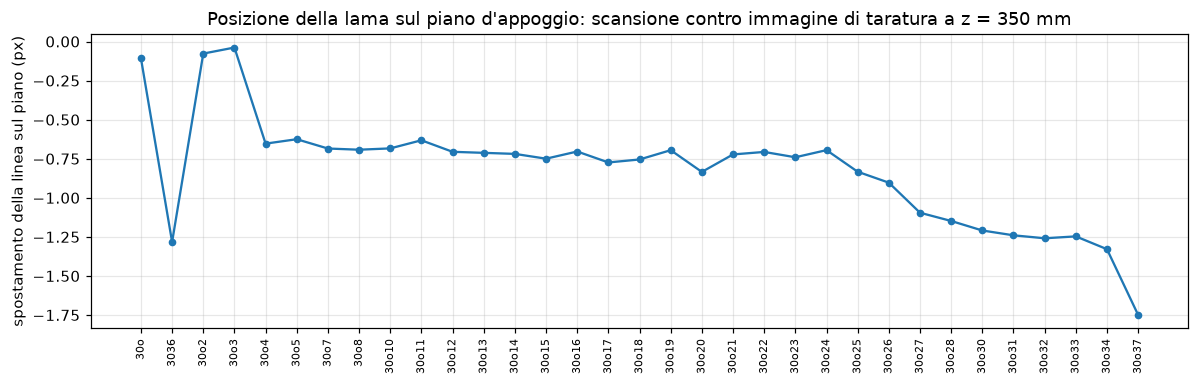

In [4]:
P, (A, B, C), center, k = calibration.model.P, calibration.plane, calibration.model.center, calibration.model.k

def pixel(z, y=0.0):
    x = (z - B * y - C) / A  # punto della lama alla quota z
    return distort_points(project(P, np.array([[x, y, z]])), center, k)[0]

per_mm = abs(pixel(300)[0] - pixel(350)[0]) / 50
print(f"1. Sensibilità: la lama si sposta di {per_mm:.2f} px per mm di quota: un pixel di errore sulla lama vale {1 / per_mm:.2f} mm di altezza.")

# 2. la linea della lama sul piano d'appoggio nelle scansioni, contro la stessa linea nell'immagine di taratura a z = 350
ref = laser_centroids(cv.imread(str(dataset.sheet_path / "30l.jpg")))
ref_u = dict(zip(ref[:, 1].round().astype(int), ref[:, 0]))
files = sorted((f for f in dataset.scans_path.glob("*.jpg")), key=lambda f: (len(f.stem), f.stem))
shifts = []
for f in files:
    uv = laser_centroids(cv.imread(str(f)))
    d = [u - ref_u[round(v)] for u, v in uv if (v < 250 or v > 1150) and round(v) in ref_u]
    shifts.append(np.median(d) if len(d) > 50 else np.nan)
print(f"2. La linea sul piano d'appoggio è spostata di {np.nanmean(shifts):+.2f} px in media rispetto alla taratura, da {np.nanmin(shifts):+.2f} a {np.nanmax(shifts):+.2f} px fra le scansioni.")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(range(len(files)), shifts, "o-", ms=4)
ax.set_xticks(range(len(files)), [f.stem for f in files], rotation=90, fontsize=7)
ax.set(ylabel="spostamento della linea sul piano (px)", title="Posizione della lama sul piano d'appoggio: scansione contro immagine di taratura a z = 350 mm")
fig.tight_layout(); fig.savefig(FIGURES / "plate_line_drift.png", bbox_inches="tight")

median_px = float(np.mean([r.median for r in results if r.role == "test"])) * per_mm
print(f"3. L'errore mediano sulle scansioni di test ({np.mean([r.median for r in results if r.role == 'test']):.2f} mm) corrisponde a {median_px:.2f} px sulla lama.")

## Cosa mostra

* **Il numero onesto è 0.9 mm, non 0.55.** Sulle 12 scansioni di test, di solidi che nessuna scelta ha mai visto, l'errore mediano medio è 0.91 mm (al peggio 1.54 mm). I 0.55 e 0.62 mm dei notebook precedenti erano di sviluppo.
* **Il setup ha una sensibilità bassa.** 0.79 px per mm di quota: un pixel di errore è 1.27 mm. L'errore sui test corrisponde a circa 0.7 px, quindi siamo vicini a quanto la geometria della triangolazione permette con questo laser e questa camera; non è un limite del codice.
* **Il banco si è mosso durante l'acquisizione.** La linea sul piano d'appoggio parte vicino alla taratura nelle prime scansioni e si sposta progressivamente fino a oltre 1 px (circa 1.5 mm) nelle ultime. Il livellamento per scansione elimina uno spostamento puro, ma dimostra che camera, laser o piano non erano fermi.
* **Le scansioni posate di traverso pesano sull'errore.** Con l'allungamento obliquo l'errore mediano sul test scende da 0.91 a circa 0.79 mm. Dove il solido è allineato alla lama la scala vale 1.00, quindi la scala di Y della calibrazione (passo di 20 mm) è corretta entro circa l'1%; dove viene 1.07-1.33 il solido è inclinato di 20-40 gradi. In un caso (30o5) peggiora: la posa è più complessa di una rotazione.\n* **Cosa non cambia il risultato.** Togliere le viste di taratura incoerenti (330, 340) o correggere la quota di ogni vista migliora l'adattamento della camera ma non l'errore sui test.